### POST CAPSTONE PROJECT
**ShopFast_Online_retailers**

**1. Data Loading and Exploration**

In [61]:
import pandas as pd
df=pd.read_csv(r"C:\Users\LENOVO\Desktop\Class notes\ShopFast_online_orders.csv")

In [62]:
df.head(10)

,order_id,order_date,region,category,customer_segment,sales,profit,quantity
0,10001,2024-03-22,North,Furniture,Corporate,323.24,68.61,1
1,10002,2024-01-15,West,Furniture,Consumer,433.66,NaN,1
2,10003,2024-01-04,East,Furniture,Consumer,111.42,-10.59,2
3,10004,2024-02-05,North,Furniture,Consumer,330.53,58.45,1
4,10005,2024-02-01,North,Furniture,Home Office,156.96,39.32,2
5,10006,2024-01-29,North,Office Supplies,Home Office,104.27,14.84,5
6,10007,2024-01-18,South,Office Supplies,Home Office,12.45,1.68,3
7,10008,2024-01-14,East,Office Supplies,Corporate,98.49,32.33,3
8,10009,2024-03-27,West,Electronics,Corporate,245.46,27.71,1
9,10010,2024-03-10,East,Office Supplies,Home Office,38.24,13.09,1


In [63]:
df.tail(20)

,order_id,order_date,region,category,customer_segment,sales,profit,quantity
4980,14981,2024-01-07,West,Office Supplies,Home Office,75.02,19.73,4
4981,14982,2024-01-02,North,Office Supplies,Home Office,35.49,9.47,4
4982,14983,2024-03-23,East,Electronics,Home Office,200.00,NaN,2
4983,14984,2024-01-21,North,Office Supplies,Corporate,47.70,NaN,7
4984,14985,2024-03-05,North,Furniture,Corporate,591.27,94.48,2
4985,14986,2024-03-01,West,Office Supplies,Home Office,150.45,34.72,9
4986,14987,2024-03-04,South,Office Supplies,Corporate,46.60,9.22,5
4987,14988,2024-01-22,East,Electronics,Home Office,149.47,7.61,3
4988,14989,2024-01-10,West,Furniture,Consumer,797.83,91.35,4
4989,14990,2024-03-03,North,Office Supplies,Consumer,61.19,18.24,8


In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   region            4984 non-null   str    
 3   category          5000 non-null   str    
 4   customer_segment  5000 non-null   str    
 5   sales             5000 non-null   float64
 6   profit            4811 non-null   float64
 7   quantity          5000 non-null   int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 486.7 KB


In [65]:
# checking the percentage of missing values (guides us whether to fill or drop)
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100})

print(missing_summary)

                  Missing_Count  Missing_Percentage
order_id                      0                0.00
order_date                    0                0.00
region                       16                0.32
category                      0                0.00
customer_segment              0                0.00
sales                         0                0.00
profit                      189                3.78
quantity                      0                0.00


In [66]:
df.describe()

,order_id,sales,profit,quantity
count,5000.000000,5000.000000,4811.000000,5000.00000
mean,12500.500000,289.714222,44.451328,2.41160
std,1443.520003,575.751047,100.529980,1.87459
min,10001.000000,2.030000,-790.290000,-5.00000
25%,11250.750000,40.322500,5.930000,1.00000
50%,12500.500000,120.835000,16.820000,2.00000
75%,13750.250000,308.437500,48.510000,3.00000
max,15000.000000,7841.740000,1337.900000,13.00000


In [67]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4995    False
4996    False
4997    False
4998    False
4999    False
Length: 5000, dtype: bool

In [68]:
df.shape

(5000, 8)

In [69]:
df.columns

Index(['order_id', 'order_date', 'region', 'category', 'customer_segment',
       'sales', 'profit', 'quantity'],
      dtype='str')

In [70]:
df["order_id"].unique()

array([10001, 10002, 10003, ..., 14998, 14999, 15000], shape=(5000,))

In [71]:
df["order_date"]

0       2024-03-22
1       2024-01-15
2       2024-01-04
3       2024-02-05
4       2024-02-01
           ...    
4995    2024-03-05
4996    2024-01-29
4997    2024-03-11
4998    2024-03-23
4999    2024-02-18
Name: order_date, Length: 5000, dtype: str

In [72]:
df["region"].unique()

<ArrowStringArray>
['North', 'West', 'East', 'South', nan]
Length: 5, dtype: str

In [73]:
df["customer_segment"].unique()

<ArrowStringArray>
['Corporate', 'Consumer', 'Home Office', 'Small Business']
Length: 4, dtype: str

In [74]:
df["sales"].unique()

array([ 323.24,  433.66,  111.42, ...,  769.04,  398.08, 1090.36],
      shape=(4654,))

In [75]:
df["profit"].unique()

array([ 68.61,    nan, -10.59, ...,  21.92, 207.64, 232.73], shape=(3581,))

In [76]:
df["quantity"].unique()

array([ 1,  2,  5,  3,  9,  4,  7,  6,  8, -2, -5, 10, 13, 11, -1, -4, 12])

In [77]:
df["order_id"].nunique()

5000

In [78]:
df["region"].nunique()

4

In [79]:
df["sales"].nunique()

4654

In [80]:
df["profit"].nunique()

3580

In [81]:
df["order_id"].value_counts()

order_id
10001    1
10002    1
10003    1
10004    1
10005    1
        ..
14996    1
14997    1
14998    1
14999    1
15000    1
Name: count, Length: 5000, dtype: int64

In [82]:
df["region"].value_counts()

region
North    1315
South    1268
West     1255
East     1146
Name: count, dtype: int64

In [83]:
df["category"].value_counts()

category
Electronics        1654
Office Supplies    1645
Furniture          1619
OFFICE SUPPLIES      16
Office supplies      12
elecTRONICS          11
electronics           8
FURNITURE             8
offiCE SUPPLIES       7
furniture             6
furnITURE             5
ELECTRONICS           5
office supplies       4
Name: count, dtype: int64

In [84]:
df["sales"].value_counts()

sales
13.38      4
13.99      3
75.78      3
22.41      3
176.33     3
          ..
3752.18    1
174.67     1
769.04     1
398.08     1
1090.36    1
Name: count, Length: 4654, dtype: int64

In [85]:
df["profit"].value_counts()

profit
3.21      6
2.16      6
7.78      6
6.56      6
2.88      6
         ..
51.29     1
752.52    1
21.92     1
207.64    1
232.73    1
Name: count, Length: 3580, dtype: int64

In [86]:
df[df.isnull().any(axis=1)]

,order_id,order_date,region,category,customer_segment,sales,profit,quantity
1,10002,2024-01-15,West,Furniture,Consumer,433.66,NaN,1
24,10025,2024-03-30,West,Office Supplies,Corporate,11.78,NaN,2
72,10073,2024-02-28,North,Office Supplies,Consumer,17.09,NaN,3
74,10075,2024-02-16,South,Office Supplies,Corporate,44.97,NaN,4
104,10105,2024-02-21,West,Electronics,Corporate,48.37,NaN,1
...,...,...,...,...,...,...,...,...
4877,14878,2024-01-10,West,Electronics,Consumer,133.29,NaN,1
4928,14929,2024-01-14,East,Electronics,Consumer,312.32,NaN,4
4947,14948,2024-02-26,North,Electronics,Consumer,101.38,NaN,3
4982,14983,2024-03-23,East,Electronics,Home Office,200.00,NaN,2


In [87]:
# checking for negative values in numeric fields
numeric_columns = [
    "order_id",
    "sales",
    "profit",
    "quantity"]

(df[numeric_columns] < 0).sum()

order_id      0
sales         0
profit      366
quantity     21
dtype: int64

**2. Data Cleaning**

In [88]:
# filling missing values/names in the region column
# Inspect the records with missing regions
df[df["region"].isna()]

,order_id,order_date,region,category,customer_segment,sales,profit,quantity
297,10298,2024-02-21,NaN,Office Supplies,Home Office,26.46,5.43,1
1551,11552,2024-01-11,NaN,Electronics,Corporate,50.03,9.57,1
1777,11778,2024-03-05,NaN,Electronics,Consumer,41.36,-3.93,1
1788,11789,2024-01-12,NaN,Furniture,Home Office,1139.12,237.07,3
1901,11902,2024-01-20,NaN,Furniture,Consumer,195.34,57.39,1
2375,12376,2024-03-05,NaN,Electronics,Corporate,87.54,16.21,3
2747,12748,2024-02-27,NaN,Office Supplies,Consumer,9.07,3.34,1
2781,12782,2024-03-23,NaN,Office Supplies,Home Office,29.13,7.20,4
2902,12903,2024-02-01,NaN,elecTRONICS,Corporate,124.87,21.22,3
3226,13227,2024-03-17,NaN,Electronics,Consumer,67.02,-1.78,1


In [89]:
# I want to avoid assigning records to the wrong region when comparing regional sales.
df["region"] = df["region"].fillna("Unknown")

In [90]:
# Verifying the result after filling with "Unknown"
df["region"].isna().sum()

np.int64(0)

In [91]:
# The category column has inconsistent capitalization
# Correcting inconsistent capitalization in the category column
df["category"]=df["category"].str.title()

In [92]:
df["category"].value_counts()

category
Office Supplies    1684
Electronics        1678
Furniture          1638
Name: count, dtype: int64

A better starting point is to calculate the typical profit margin for each product category, provided each category has enough valid observations.

For example, if Electronics has an average profit margin of 15%, a missing profit for an Electronics order with sales of 200 could initially be estimated as:
\[200\times 15\%=30\]

However, we must account for negative profits, extreme margins, and differences between individual orders. The method also assumes that the observed margins are representative of the missing cases.

1.calculate the profit margin for rows where both sales and profit are available and sales are nonzero.

In [93]:
df["profit_margin"] = (df["profit"] / df["sales"])

In [94]:
df.head(10)

,order_id,order_date,region,category,customer_segment,sales,profit,quantity,profit_margin
0,10001,2024-03-22,North,Furniture,Corporate,323.24,68.61,1,0.212257
1,10002,2024-01-15,West,Furniture,Consumer,433.66,NaN,1,NaN
2,10003,2024-01-04,East,Furniture,Consumer,111.42,-10.59,2,-0.095046
3,10004,2024-02-05,North,Furniture,Consumer,330.53,58.45,1,0.176837
4,10005,2024-02-01,North,Furniture,Home Office,156.96,39.32,2,0.250510
5,10006,2024-01-29,North,Office Supplies,Home Office,104.27,14.84,5,0.142323
6,10007,2024-01-18,South,Office Supplies,Home Office,12.45,1.68,3,0.134940
7,10008,2024-01-14,East,Office Supplies,Corporate,98.49,32.33,3,0.328257
8,10009,2024-03-27,West,Electronics,Corporate,245.46,27.71,1,0.112890
9,10010,2024-03-10,East,Office Supplies,Home Office,38.24,13.09,1,0.342312


In [95]:
profit_margin = df['profit'] / df['sales']

category_margins = profit_margin.groupby(df['category']).mean()

df['profit'] = df['profit'].fillna(df['sales'] * df['category'].map(category_margins))

In [96]:
df.head(15)

,order_id,order_date,region,category,customer_segment,sales,profit,quantity,profit_margin
0,10001,2024-03-22,North,Furniture,Corporate,323.24,68.610000,1,0.212257
1,10002,2024-01-15,West,Furniture,Consumer,433.66,73.910687,1,NaN
2,10003,2024-01-04,East,Furniture,Consumer,111.42,-10.590000,2,-0.095046
3,10004,2024-02-05,North,Furniture,Consumer,330.53,58.450000,1,0.176837
4,10005,2024-02-01,North,Furniture,Home Office,156.96,39.320000,2,0.250510
5,10006,2024-01-29,North,Office Supplies,Home Office,104.27,14.840000,5,0.142323
6,10007,2024-01-18,South,Office Supplies,Home Office,12.45,1.680000,3,0.134940
7,10008,2024-01-14,East,Office Supplies,Corporate,98.49,32.330000,3,0.328257
8,10009,2024-03-27,West,Electronics,Corporate,245.46,27.710000,1,0.112890
9,10010,2024-03-10,East,Office Supplies,Home Office,38.24,13.090000,1,0.342312


In [97]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   region            5000 non-null   str    
 3   category          5000 non-null   str    
 4   customer_segment  5000 non-null   str    
 5   sales             5000 non-null   float64
 6   profit            5000 non-null   float64
 7   quantity          5000 non-null   int64  
 8   profit_margin     4811 non-null   float64
dtypes: float64(3), int64(2), str(4)
memory usage: 525.9 KB


In [98]:
# Removing the added column of profit_margin
df=df.drop(columns='profit_margin')

In [99]:
df.head()

,order_id,order_date,region,category,customer_segment,sales,profit,quantity
0,10001,2024-03-22,North,Furniture,Corporate,323.24,68.610000,1
1,10002,2024-01-15,West,Furniture,Consumer,433.66,73.910687,1
2,10003,2024-01-04,East,Furniture,Consumer,111.42,-10.590000,2
3,10004,2024-02-05,North,Furniture,Consumer,330.53,58.450000,1
4,10005,2024-02-01,North,Furniture,Home Office,156.96,39.320000,2


In [100]:
df['order_date'].unique()

<ArrowStringArray>
['2024-03-22', '2024-01-15', '2024-01-04', '2024-02-05', '2024-02-01',
 '2024-01-29', '2024-01-18', '2024-01-14', '2024-03-27', '2024-03-10',
 ...
 '02/03/2024', '03/10/2024', '01/31/2024', '02/28/2024', '01/14/2024',
 '01/12/2024', '01/23/2024', '02/08/2024', '01/06/2024', '03/19/2024']
Length: 126, dtype: str

In [101]:
# converting dates into proper date time values
# my dates currently are in text format(Str). 
# my dataset contains mixed date types some of which are ISO and American
df["order_date"] = pd.to_datetime(df["order_date"],format="mixed",dayfirst=False)

In [102]:
df['order_date'].unique()

<DatetimeArray>
['2024-03-22 00:00:00', '2024-01-15 00:00:00', '2024-01-04 00:00:00',
 '2024-02-05 00:00:00', '2024-02-01 00:00:00', '2024-01-29 00:00:00',
 '2024-01-18 00:00:00', '2024-01-14 00:00:00', '2024-03-27 00:00:00',
 '2024-03-10 00:00:00', '2024-01-12 00:00:00', '2024-03-16 00:00:00',
 '2024-02-24 00:00:00', '2024-01-05 00:00:00', '2024-01-28 00:00:00',
 '2024-01-30 00:00:00', '2024-03-05 00:00:00', '2024-03-18 00:00:00',
 '2024-03-12 00:00:00', '2024-01-26 00:00:00', '2024-03-24 00:00:00',
 '2024-03-30 00:00:00', '2024-02-23 00:00:00', '2024-02-27 00:00:00',
 '2024-01-01 00:00:00', '2024-01-21 00:00:00', '2024-02-13 00:00:00',
 '2024-01-20 00:00:00', '2024-02-18 00:00:00', '2024-01-13 00:00:00',
 '2024-02-15 00:00:00', '2024-02-14 00:00:00', '2024-02-03 00:00:00',
 '2024-01-06 00:00:00', '2024-02-28 00:00:00', '2024-03-09 00:00:00',
 '2024-01-16 00:00:00', '2024-01-11 00:00:00', '2024-03-11 00:00:00',
 '2024-02-07 00:00:00', '2024-03-21 00:00:00', '2024-03-20 00:00:00',
 '20

**3.Saving the cleaned data**

In [103]:
# Saving cleaned data
df.to_csv("clean_ShopFast_online_orders.csv",index=False)

In [104]:
import pandas as pd
df1=pd.read_csv("clean_ShopFast_online_orders.csv")

In [105]:
df.head(10)

,order_id,order_date,region,category,customer_segment,sales,profit,quantity
0,10001,2024-03-22,North,Furniture,Corporate,323.24,68.610000,1
1,10002,2024-01-15,West,Furniture,Consumer,433.66,73.910687,1
2,10003,2024-01-04,East,Furniture,Consumer,111.42,-10.590000,2
3,10004,2024-02-05,North,Furniture,Consumer,330.53,58.450000,1
4,10005,2024-02-01,North,Furniture,Home Office,156.96,39.320000,2
5,10006,2024-01-29,North,Office Supplies,Home Office,104.27,14.840000,5
6,10007,2024-01-18,South,Office Supplies,Home Office,12.45,1.680000,3
7,10008,2024-01-14,East,Office Supplies,Corporate,98.49,32.330000,3
8,10009,2024-03-27,West,Electronics,Corporate,245.46,27.710000,1
9,10010,2024-03-10,East,Office Supplies,Home Office,38.24,13.090000,1


In [106]:
df1.tail(10)

,order_id,order_date,region,category,customer_segment,sales,profit,quantity
4990,14991,2024-02-11,East,Office Supplies,Corporate,49.20,15.71,4
4991,14992,2024-01-31,South,Furniture,Home Office,459.20,44.47,2
4992,14993,2024-02-12,North,Electronics,Consumer,83.47,10.00,1
4993,14994,2024-02-05,South,Electronics,Consumer,188.22,32.91,2
4994,14995,2024-01-07,North,Furniture,Consumer,530.09,51.29,4
4995,14996,2024-03-05,North,Electronics,Consumer,3752.18,752.52,4
4996,14997,2024-01-29,West,Electronics,Consumer,174.67,21.92,1
4997,14998,2024-03-11,West,Furniture,Corporate,769.04,207.64,3
4998,14999,2024-03-23,North,Electronics,Home Office,398.08,25.09,1
4999,15000,2024-02-18,North,Electronics,Consumer,1090.36,232.73,1


In [107]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   region            5000 non-null   str    
 3   category          5000 non-null   str    
 4   customer_segment  5000 non-null   str    
 5   sales             5000 non-null   float64
 6   profit            5000 non-null   float64
 7   quantity          5000 non-null   int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 486.2 KB


In [108]:
df1.isnull().sum()

order_id            0
order_date          0
region              0
category            0
customer_segment    0
sales               0
profit              0
quantity            0
dtype: int64

**4. Data Analysis**

**Q1. Which region has the highest total profit? Which has the lowest? (Bar Chart)**

In [109]:
highest_total_profit=df1.groupby("region")["profit"].sum()
highest_total_profit

region
East       54603.481679
North      59655.119738
South      55838.206031
Unknown      564.110000
West       51062.193746
Name: profit, dtype: float64

In [110]:
highest_total_profit.idxmax()

'North'

In [111]:
lowest_total_profit=df1.groupby("region")["profit"].sum()
lowest_total_profit

region
East       54603.481679
North      59655.119738
South      55838.206031
Unknown      564.110000
West       51062.193746
Name: profit, dtype: float64

In [112]:
lowest_total_profit.idxmin()

'Unknown'

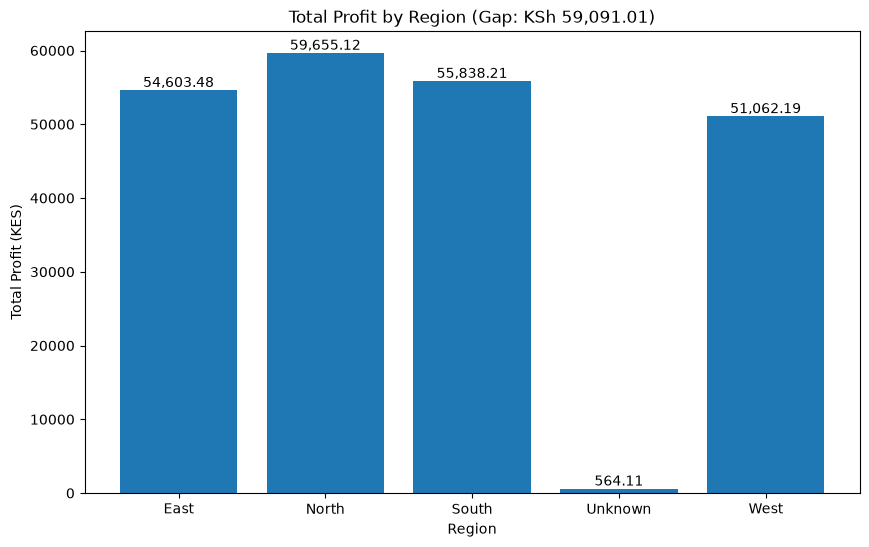

In [113]:
import matplotlib.pyplot as plt

# Total profit by region
profit = {
    "East": 54603.48,
    "North": 59655.12,
    "South": 55838.21,
    "Unknown": 564.11,
    "West": 51062.19
}

# Plot all five regions
plt.figure(figsize=(10, 6))
plt.bar(profit.keys(), profit.values())

# Identify highest and lowest profit
highest = max(profit.values())
lowest = min(profit.values())

# Add value labels
for i, value in enumerate(profit.values()):
    plt.text(i, value, f"{value:,.2f}",
             ha="center", va="bottom")

# Add performance gap
plt.title(f"Total Profit by Region (Gap: KSh {highest-lowest:,.2f})")
plt.xlabel("Region")
plt.ylabel("Total Profit (KES)")

plt.show()

**Q2. Within Electronics, which customer segment has the highest average profit per order?** 

**Customer segment with highest average profit per order on Bar Chart + Summary Table**

In [114]:
# Filter Electronics and calculate average profit by customer segment
df1[df1["category"] == "Electronics"].groupby("customer_segment")["profit"].mean().sort_values(ascending=False)

customer_segment
Small Business    140.540000
Consumer           64.248954
Home Office        60.914287
Corporate          52.295179
Name: profit, dtype: float64

In [115]:
# To get only the customer segment with the highest average profit:
df1[df1["category"] == "Electronics"].groupby("customer_segment")["profit"].mean().idxmax()

'Small Business'

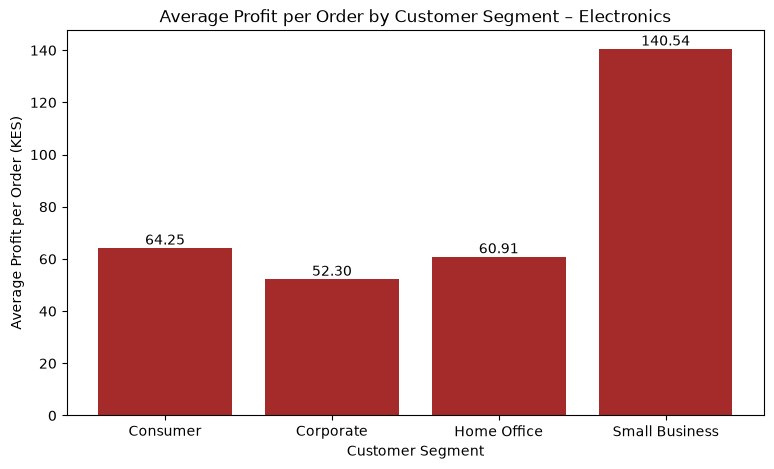

In [116]:
import matplotlib.pyplot as plt
# Filter Electronics and calculate average profit per customer segment
electronics = df1[df1["category"] == "Electronics"]

avg_profit = electronics.groupby("customer_segment")["profit"].mean()

# Plot bar chart
plt.figure(figsize=(9, 5))
plt.bar(avg_profit.index, avg_profit.values,color="brown")

# Add labels
plt.title("Average Profit per Order by Customer Segment – Electronics")
plt.xlabel("Customer Segment")
plt.ylabel("Average Profit per Order (KES)")

# Display values on bars
for i, value in enumerate(avg_profit.values):
    plt.text(i, value, f"{value:,.2f}", ha="center", va="bottom")

plt.show()

**Summary Table**
To show
Column	Meaning

`Total_Orders`	Number of orders per customer segment

`Average_Profit`	Average profit per order

`Total_Profit`	Total profit generated by the segment

In [117]:
# Filter Electronics
electronics = df1[df1["category"] == "Electronics"]

# Create summary table
summary_table = electronics.groupby("customer_segment").agg(
    Total_Orders=("order_id", "count"),
    Average_Profit=("profit", "mean"),
    Total_Profit=("profit", "sum")
).sort_values(by="Average_Profit", ascending=False)

# Display summary table
summary_table

,Total_Orders,Average_Profit,Total_Profit
customer_segment,,,
Small Business,3,140.540000,421.620000
Consumer,549,64.248954,35272.675721
Home Office,548,60.914287,33381.029040
Corporate,578,52.295179,30226.613504


**Q3. How does profit trend over three months?** 

**Profit trend over three months (up, down, or flat) Line Chart + Trend Line**

In [124]:
# converting dates into proper date time values
# my dates currently are in text format(Str). 
# my dataset contains mixed date types some of which are ISO and American
df1["order_date"] = pd.to_datetime(df1["order_date"],format="mixed",dayfirst=False)

In [125]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          5000 non-null   int64         
 1   order_date        5000 non-null   datetime64[us]
 2   region            5000 non-null   str           
 3   category          5000 non-null   str           
 4   customer_segment  5000 non-null   str           
 5   sales             5000 non-null   float64       
 6   profit            5000 non-null   float64       
 7   quantity          5000 non-null   int64         
dtypes: datetime64[us](1), float64(2), int64(2), str(3)
memory usage: 437.4 KB


In [126]:
# Step 1: Calculate total profit for each month
df1["order_date"] = pd.to_datetime(df1["order_date"])

df1["month"] = df1["order_date"].dt.month_name()

df1["month_number"] = df1["order_date"].dt.month

monthly_profit = df1.groupby(["month_number", "month"])["profit"].sum()

monthly_profit = monthly_profit.sort_index(level="month_number")

print(monthly_profit)

month_number  month   
1             January     76265.843041
2             February    71198.689026
3             March       74258.579129
Name: profit, dtype: float64


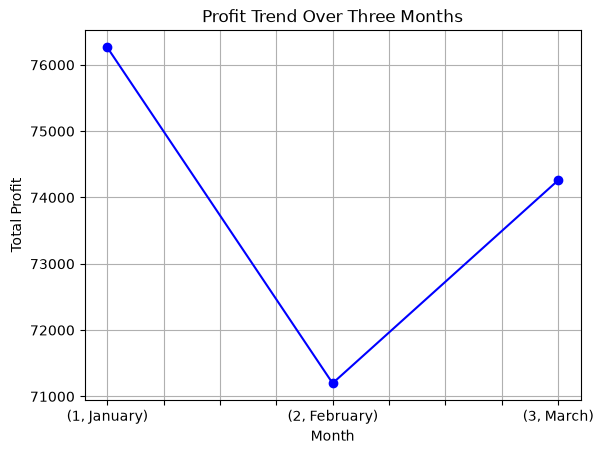

In [127]:
# Step 2: Plot the line chart
import matplotlib.pyplot as plt

monthly_profit.plot(kind="line", marker="o", color="blue")

plt.title("Profit Trend Over Three Months")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.grid(True)

plt.show()

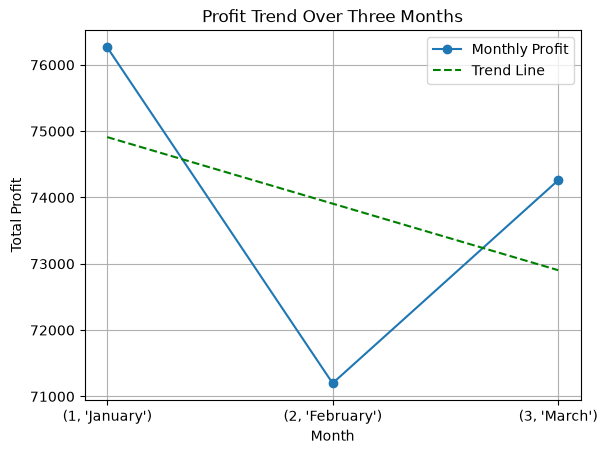

In [128]:
# Step 3: Add a trend line
import numpy as np

x = range(len(monthly_profit))
y = monthly_profit.values

trend = np.polyfit(x, y, 1)

plt.plot(x, y, marker="o", label="Monthly Profit")
plt.plot(x, np.polyval(trend, x), linestyle="--", label="Trend Line",color="green")

plt.title("Profit Trend Over Three Months")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(x, monthly_profit.index)
plt.legend()
plt.grid(True)

plt.show()

**Recommendations for ShopFast online sales**

**Recommendation 1: Regional Profitability Performance**

From the analysis, the North region emerged as the best-performing region, recording the highest total profit of KSh 59,655.12, followed by South at KSh 55,838.21, East at KSh 54,603.48 and West at KSh 51,062.19. Although North ranked first among the four regions, the differences in total profit were relatively small, suggesting that regional profitability was fairly comparable.

North's performance nevertheless presents an opportunity for further comparative analysis to establish the factors contributing to its relatively higher profitability. In particular, examining differences in product sales mix, customer purchasing patterns, product combinations and sales volumes across regions could reveal whether North's performance is driven by particular products or customer segments. Additionally, comparing sales performance across regions could help establish whether differences in sales-team productivity contribute to the observed profitability gap.

These comparisons would provide a clearer understanding of the factors associated with North's stronger performance and establish whether similar patterns exist in the other regions.

**Recommendation 2: customer segment with the highest average profit**

**Analysis of Profit Performance by Customer Segment within Electronics**

The analysis indicates that the Small Business customer segment recorded the highest average profit per order within the Electronics category, at **140.54**, followed by Consumer at **64.25**, Home Office at **60.91**, and Corporate at **52.30**.

Interestingly, despite recording the highest average profit per order, the Small Business segment had only 3 orders. This is considerably lower than the other customer segments, which recorded substantially higher order volumes. Corporate had the highest number of orders at 578, followed by Consumer with 549 and Home Office with 548.

Despite having the highest order volume, Corporate recorded the lowest average profit per order and a total profit of 30,226.61. Consumer, on the other hand, generated the highest total profit of **35,272.68**, followed by Home Office at **33,381.03** and Corporate at **30,226.61**.

These findings suggest that a higher order volume does not necessarily translate into higher average profit per order or higher total profit. The profitability of each customer segment may also depend on factors such as order value, product pricing, discounts, and operating costs.

Although Small Business recorded the highest average profit per order, its total contribution to profit was only 421.62 because of its very low order volume. This demonstrates the importance of considering both average profit per order and total profit when evaluating customer segment performance.

Recommendations

1. Investigate the Small Business segment on why Small Business orders generate significantly higher average profits than other customer segments. Particular attention should be given to pricing, order values, discount levels, and product combinations. However, since the finding is based on only three orders, more data should be collected before making major business decisions.

2. Strengthening the Consumer segment should remain a key focus because this segment generated the highest total profit of 35,272.68. The busness should explore strategies to retain these customers, increase repeat purchases, and identify opportunities to improve their average profit per order and also help other segments learn from this if the aim is to maximize total profit.

3. Review Corporate segment profitability although Corporate recorded the highest number of orders (578), it generated the lowest average profit per order (52.30) among the three major segments. This should be investigated whether to find out whether high discounts, lower selling prices, or other costs are reducing profitability. Strategies should focus on improving profit margins without necessarily sacrificing order volume.

4. Balancing of order volumes versus profitability should be done avoid relying solely on order volume when assessing business performance. Instead, decisions should consider average profit per order alongside total profit to identify customer segments that offer both sustainable sales volumes and stronger profit contributions.

**Recommendation 3: Profit trends over 3 months**

The analysis indicates that January recorded the highest total profit of 76,265.84, followed by March at 74,258.58, while February recorded the lowest total profit of 71,198.69. This shows a decline in profitability from January to February, followed by a recovery in March. However, March's profit did not fully return to January's level. Overall, the three months reflect relatively consistent profit performance, although the figures suggest some fluctuations in monthly profitability.

I recommend that ShopFast management investigate the factors that contributed to the sharp decline in profitability in February. Additionally, management should identify the strategies or operational measures that contributed to the recovery in March and assess whether they can be sustained or replicated in subsequent months to improve overall profitability.